# 4902736

PROVOR CTS5 float 4902736 observes consistent oxygen spikes with offset (?). Note that the spikes above the basline between ~1200-400m seem more in line with the deeper data than the baseline does? I will check TEMP_DOXY and PHASE to see where this is coming from. 

In [14]:
from pathlib import Path

import xarray as xr
import seaborn as sns
import matplotlib.pyplot as plt

import argopy

wmo = 4902736
argopy.dashboard(wmo, 2, type='bgc')


(2050.0, -50.0)

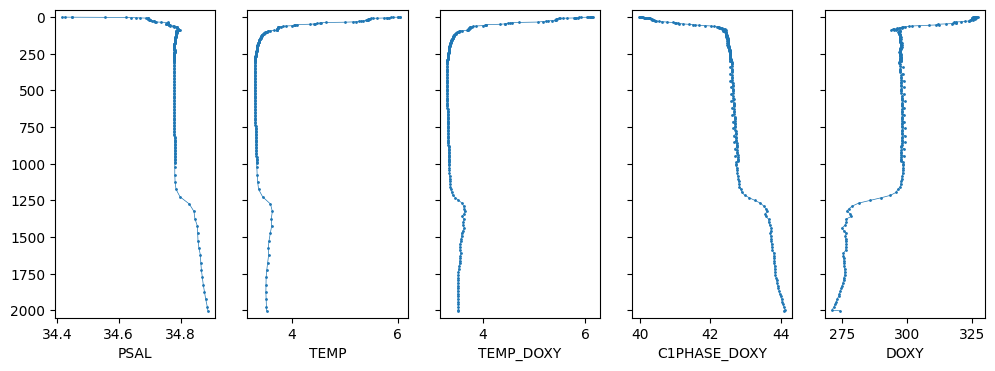

In [15]:
# sorry for the hard coded file paths
core_file = Path(f'/Users/GordonC/Documents/data/Argo/dac/meds/{wmo}/profiles/R{wmo}_002.nc')
bgc_file  = Path(f'/Users/GordonC/Documents/data/Argo/dac/meds/{wmo}/profiles/BR{wmo}_002.nc')

core = xr.open_dataset(core_file, decode_timedelta=False)
bgc  = xr.open_dataset(bgc_file, decode_timedelta=False)

fig, axes = plt.subplots(1, 5, sharey=True)
for ax, v in zip(axes, ['PSAL', 'TEMP', 'TEMP_DOXY', 'C1PHASE_DOXY', 'DOXY']):
    data = core if v in ['TEMP', 'PSAL'] else bgc
    ax.plot(data[v].data.flatten(), data['PRES'].data.flatten(), '-o', lw=0.5, markersize=1)
    ax.set_xlabel(v)

fig.set_size_inches(12, 4)
ax.set_ylim((2050, -50))


So, the source is from the oxygen sensor (see the reflected spikiness in C1PHASE_DOXY).